# Практическая работа: многослойные нейронные сети

В работе сравнивается полносвязная нейронная сеть на CIFAR-10 и датасете дорожных знаков GTSRB.

## 1. Усложните модель (только `nn.Linear`)

Добавим несколько полносвязных слоёв с функцией активации ReLU. Свёрточные слои не используются.

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_random_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class NeuralNetwork(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

## 2. Добавьте расчёт train/val метрик

Будем считать среднюю функцию потерь и accuracy на обучающей и валидационной выборках.

In [ ]:
def train_epoch(dataloader, model, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(dataloader, model, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

def fit_model(model, train_loader, val_loader, epochs=3, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss, train_acc = train_epoch(train_loader, model, criterion, optimizer)
        val_loss, val_acc = evaluate(val_loader, model, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Эпоха {epoch + 1}/{epochs}: "
              f"train loss={train_loss:.4f}, train acc={train_acc:.4f}, "
              f"val loss={val_loss:.4f}, val acc={val_acc:.4f}")
    return history

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="train")
    plt.plot(epochs, history["val_loss"], label="validation")
    plt.xlabel("Эпоха")
    plt.ylabel("Loss")
    plt.title(title + ": loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="train")
    plt.plot(epochs, history["val_acc"], label="validation")
    plt.xlabel("Эпоха")
    plt.ylabel("Accuracy")
    plt.title(title + ": accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 3. Обучите модель на CIFAR-10

Изображения приводятся к размеру 32×32 и преобразуются в тензоры. Для обучения выделим часть тренировочной выборки, а test оставим для финальной проверки.

In [ ]:
batch_size = 128
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

cifar_full = datasets.CIFAR10(root="./data", train=True, download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)

train_size = int(0.9 * len(cifar_full))
val_size = len(cifar_full) - train_size
cifar_train, cifar_val = random_split(
    cifar_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

cifar_train_loader = DataLoader(cifar_train, batch_size=batch_size, shuffle=True, num_workers=0)
cifar_val_loader = DataLoader(cifar_val, batch_size=batch_size, shuffle=False, num_workers=0)
cifar_test_loader = DataLoader(cifar_test, batch_size=batch_size, shuffle=False, num_workers=0)

cifar_model = NeuralNetwork(3 * 32 * 32, 10).to(device)
print(cifar_model)

100%|██████████| 170M/170M [14:37<00:00, 194kB/s]


NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
cifar_history = fit_model(cifar_model, cifar_train_loader, cifar_val_loader, epochs=3)

Эпоха 1/3: train loss=1.6710, train acc=0.4028, val loss=1.5411, val acc=0.4548
Эпоха 2/3: train loss=1.4484, train acc=0.4877, val loss=1.4306, val acc=0.4960
Эпоха 3/3: train loss=1.3302, train acc=0.5312, val loss=1.4093, val acc=0.5062


## 4. Возьмите более сложный датасет, связанный с транспортом

В качестве дополнительного набора используется GTSRB — изображения дорожных знаков. В нём 43 класса. Изображения приводятся к единому размеру 32×32.

In [ ]:
gtsrb_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

gtsrb_train_full = datasets.GTSRB(
    root="./data", split="train", download=True, transform=gtsrb_transform
)
gtsrb_test = datasets.GTSRB(
    root="./data", split="test", download=True, transform=gtsrb_transform
)

gtsrb_train_size = int(0.9 * len(gtsrb_train_full))
gtsrb_val_size = len(gtsrb_train_full) - gtsrb_train_size
gtsrb_train, gtsrb_val = random_split(
    gtsrb_train_full, [gtsrb_train_size, gtsrb_val_size],
    generator=torch.Generator().manual_seed(42)
)

gtsrb_train_loader = DataLoader(gtsrb_train, batch_size=batch_size, shuffle=True, num_workers=0)
gtsrb_val_loader = DataLoader(gtsrb_val, batch_size=batch_size, shuffle=False, num_workers=0)
gtsrb_test_loader = DataLoader(gtsrb_test, batch_size=batch_size, shuffle=False, num_workers=0)

print("Train:", len(gtsrb_train), "Validation:", len(gtsrb_val), "Test:", len(gtsrb_test))

100%|██████████| 187M/187M [00:14<00:00, 13.0MB/s]
100%|██████████| 89.0M/89.0M [00:08<00:00, 10.7MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 287kB/s]


Train: 23976 Validation: 2664 Test: 12630


## 5. Попробуйте обучить модель на GTSRB

In [ ]:
gtsrb_model = NeuralNetwork(3 * 32 * 32, 43).to(device)
gtsrb_history = fit_model(gtsrb_model, gtsrb_train_loader, gtsrb_val_loader, epochs=3)

Эпоха 1/3: train loss=1.9484, train acc=0.4424, val loss=1.2599, val acc=0.6186
Эпоха 2/3: train loss=0.8352, train acc=0.7475, val loss=0.6027, val acc=0.8041
Эпоха 3/3: train loss=0.5554, train acc=0.8325, val loss=0.4439, val acc=0.8529


## 6. Посчитайте количество параметров модели

In [ ]:
print("Параметров модели CIFAR-10:", f"{count_parameters(cifar_model):,}")
print("Параметров модели GTSRB:", f"{count_parameters(gtsrb_model):,}")

Параметров модели CIFAR-10: 1,738,890
Параметров модели GTSRB: 1,743,147


## 7. Визуализируйте loss и метрики

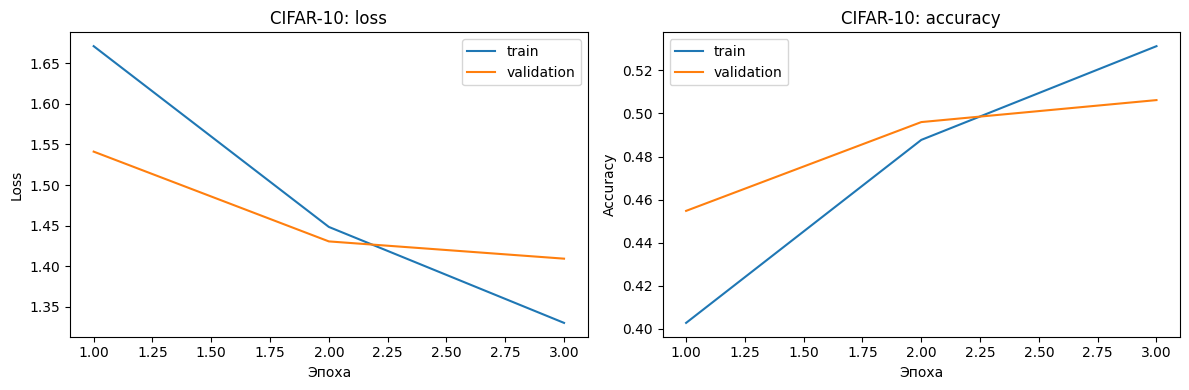

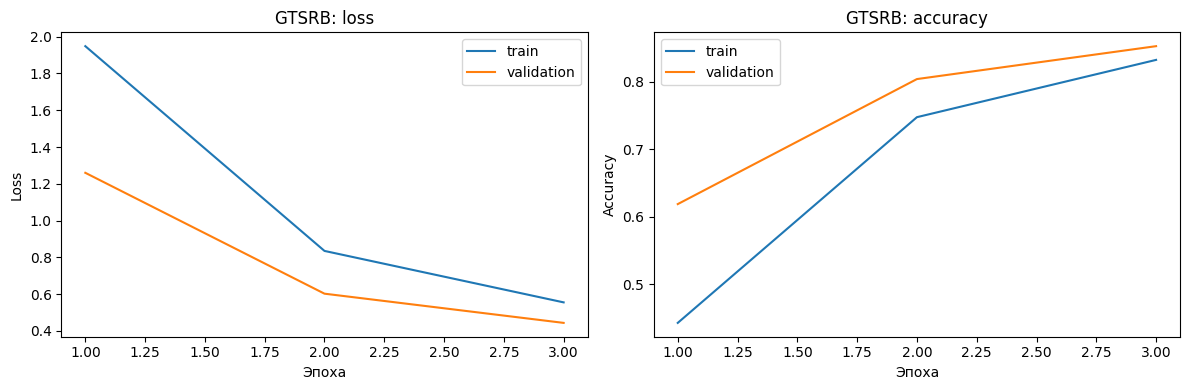

In [ ]:
plot_history(cifar_history, "CIFAR-10")
plot_history(gtsrb_history, "GTSRB")

## 8. Проверьте финальное качество на test выборке

In [ ]:
criterion = nn.CrossEntropyLoss()

cifar_test_loss, cifar_test_acc = evaluate(cifar_test_loader, cifar_model, criterion)
gtsrb_test_loss, gtsrb_test_acc = evaluate(gtsrb_test_loader, gtsrb_model, criterion)

print(f"CIFAR-10: test loss={cifar_test_loss:.4f}, test accuracy={cifar_test_acc:.4f}")
print(f"GTSRB:    test loss={gtsrb_test_loss:.4f}, test accuracy={gtsrb_test_acc:.4f}")

CIFAR-10: test loss=1.3962, test accuracy=0.5136
GTSRB:    test loss=1.0742, test accuracy=0.7149
